# Benchmark: zinc on the Meuse floodplain

Twelve models of topsoil zinc at 155 locations on the Meuse floodplain {cite:p}`pebesma2005classes`, scored on held-out locations over 20 shared 80/20 splits. The published analysis regresses log zinc on the square root of distance to the river, elevation, flooding frequency and soil, and then kriges the residuals {cite:p}`burrough1998principles`: it interpolates the regression residuals between sampled locations with a spatial covariance model (a Gaussian process). The question here is how much each way of adding location (a smooth surface, kriging, a tree on the coordinates, or trees on everything) improves on that trend, on 124 training points. The metric is held-out RMSE of log zinc; lower is better.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how twelve models of log zinc score on held-out Meuse sampling locations |
| **Observed response** | log of topsoil zinc concentration (ppm) |
| **Estimand** | held-out root mean squared error on the log scale; MAE and R² alongside |
| **Units** | log ppm |
| **Sampling unit** | one topsoil sampling location |
| **Dependence** | spatially correlated; random splits put neighbours on both sides, so the scores measure interpolation between sampled points, not extrapolation to new areas |
| **Split / resampling unit** | the location; the same 20 random 80/20 splits for every method |
| **Tuning** | `tune_mstop` (5-fold CV) for mboostrs; `gridsearch` for pyGAM; maximum likelihood for the kriging kernel; 400 rounds at learning rate 0.05 for the trees, plus a LightGBM arm with rounds chosen by 5-fold CV early stopping |
| **Uncertainty** | across-split standard errors and paired per-split differences against the published OLS trend |
| **Claim type** | predictive comparison of interpolation under random splits on 155 points; not evidence about mapping new areas |
:::

In [1]:
from IPython.display import display
import altair as alt
import numpy as np
import polars as pl

from public_tasks import (
    failures, lines, load, memory, paired, protocol, summary, table, warnings_by_method,
)

bench, runs = load("spatial")
display(table(
    protocol(bench), stub="item", stubhead="Item",
    title="What was run", subtitle="Pinned source, shared splits, one thread per library",
    notes=["Source: bench_public_spatial.json, written by benches/bench_public_tasks.py."],
))

GT(_tbl_data=shape: (11, 2)
┌───────────────────────┬─────────────────────────────────┐
│ item                  ┆ value                           │
│ ---                   ┆ ---                             │
│ str                   ┆ str                             │
╞═══════════════════════╪═════════════════════════════════╡
│ source                ┆ https://raw.githubusercontent.… │
│ source sha256         ┆ b27776bc1cad63c4…               │
│ train fraction        ┆ 0.8                             │
│ seeds (random splits) ┆ 20                              │
│ trees (fixed setting) ┆ 400 rounds, learning rate 0.05  │
│ …                     ┆ …                               │
│ versions              ┆ mboostrs 0.1.3, polars 2.0.0, … │
│ commit                ┆ 836c450c8c + uncommitted runne… │
│ runner sha256         ┆ ccd6242f4a5b001a…               │
│ measured at (UTC)     ┆ 2026-10-08T22:25:20+00:00       │
│ machine               ┆ Intel(R) Xeon(R) Processor, 8 … │
└───────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10de4fc20>, _boxhead=Boxhead([ColInfo(var='item', type=<ColInfoTypeEnum.stub: 2>, column_label='item', column_align='left', column_width=None), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='value', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10f8c7650>, _spanners=Spanners([]), _heading=Heading(title='What was run', subtitle='Pinned source, shared splits, one thread per library', preheader=None), _stubhead='Item', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c55aa80>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10de9e360>, _source_notes=['Source: bench_public_spatial.json, written by benches/bench_public_tasks.py.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10deceba0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10ef9a270>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border

## Held-out scores

In [2]:
ORDER_KEY = pl.col("method").replace_strict({'CatBoost': 0, 'mboostrs + btree(x, y)': 1, 'XGBoost': 2, 'sklearn HGB': 3, 'LightGBM (CV rounds)': 4, 'LightGBM': 5, 'regression kriging (OLS + GP)': 6, 'mboostrs + bspatial': 7, 'pyGAM LinearGAM + te(x, y)': 8, 'mboostrs autospec': 9, 'mboostrs covariates': 10, 'statsmodels OLS (published trend)': 11}, default=99)
scores = summary(runs, ["rmse", "mae", "r2"]).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o")
display(table(
    scores.select("method", "rmse", "rmse_se", "mae", "r2", "failed", "seconds"),
    stub="method", stubhead="Method",
    title="Held-out scores for log zinc on the Meuse floodplain",
    subtitle="Mean over 20 shared 80/20 splits of 155 locations",
    labels={"rmse": "RMSE ↓", "rmse_se": "± SE", "mae": "MAE ↓", "r2": "R² ↑", "failed": "failed", "seconds": "s"},
    better={"rmse": "min", "mae": "min", "r2": "max"},
    formats={"rmse_se": 3, "seconds": 2}, decimals=3,
    notes=["The covariate set is distance to the river, elevation, flooding frequency, soil type "
           "and lime; the trees, pyGAM and kriging also see the coordinates. s is the median "
           "seconds for the whole workflow. failed counts seeds that raised."],
))
display(table(
    paired(runs, "rmse", "statsmodels OLS (published trend)").with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Paired RMSE difference from the published OLS trend",
    subtitle="Mean over splits of (method − OLS on √dist, elevation, flooding, soil, lime); negative is better",
    labels={"pairs": "splits", "difference": "Δ RMSE", "difference_se": "± SE"},
    better={"difference": "min"}, decimals=3,
    notes=["SE is the standard deviation of the per-split difference over the square root of the pairs."],
))

GT(_tbl_data=shape: (12, 7)
┌─────────────────────────────────┬──────────┬──────────┬──────────┬──────────┬────────┬───────────┐
│ method                          ┆ rmse     ┆ rmse_se  ┆ mae      ┆ r2       ┆ failed ┆ seconds   │
│ ---                             ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---    ┆ ---       │
│ str                             ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ u32    ┆ f64       │
╞═════════════════════════════════╪══════════╪══════════╪══════════╪══════════╪════════╪═══════════╡
│ CatBoost                        ┆ 0.290061 ┆ 0.007678 ┆ 0.22321  ┆ 0.833979 ┆ 0      ┆ 0.064179  │
│ mboostrs + btree(x, y)          ┆ 0.299716 ┆ 0.008922 ┆ 0.233252 ┆ 0.822061 ┆ 0      ┆ 0.029213  │
│ XGBoost                         ┆ 0.301769 ┆ 0.008258 ┆ 0.236106 ┆ 0.821683 ┆ 0      ┆ 0.063029  │
│ sklearn HGB                     ┆ 0.301813 ┆ 0.011074 ┆ 0.23509  ┆ 0.818326 ┆ 0      ┆ 0.094058  │
│ LightGBM (CV rounds)            ┆ 0.309788 ┆ 0.010027 ┆ 0.239    ┆ 0.810006 ┆ 0      ┆ 0.06463   │
│ …                               ┆ …        ┆ …        ┆ …        ┆ …        ┆ …      ┆ …         │
│ mboostrs + bspatial             ┆ 0.343322 ┆ 0.011169 ┆ 0.252196 ┆ 0.767324 ┆ 0      ┆ 2.083014  │
│ pyGAM LinearGAM + te(x, y)      ┆ 0.349907 ┆ 0.011426 ┆ 0.268888 ┆ 0.758033 ┆ 0      ┆ 0.288803  │
│ mboostrs autospec               ┆ 0.356586 ┆ 0.013314 ┆ 0.254025 ┆ 0.75166  ┆ 6      ┆ 16.216713 │
│ mboostrs covariates             ┆ 0.368927 ┆ 0.00849  ┆ 0.288909 ┆ 0.734836 ┆ 0      ┆ 0.011059  │
│ statsmodels OLS (published tre… ┆ 0.380028 ┆ 0.00857  ┆ 0.306723 ┆ 0.718474 ┆ 0      ┆ 0.001715  │
└─────────────────────────────────┴──────────┴──────────┴──────────┴──────────┴────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10f866db0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='rmse', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE ↓', column_align='right', column_width=None), ColInfo(var='rmse_se', type=<ColInfoTypeEnum.default: 1>, column_label='± SE', column_align='right', column_width=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE ↓', column_align='right', column_width=None), ColInfo(var='r2', type=<ColInfoTypeEnum.default: 1>, column_label='R² ↑', column_align='right', column_width=None), ColInfo(var='failed', type=<ColInfoTypeEnum.default: 1>, column_label='failed', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e0d01d0>, _spanners=Spanners([]), _heading=Heading(title='Held-out scores for log zinc on the Meuse floodplain', subtitle='Mean over 20 shared 80/20 splits of 155 locations', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10e0aba70>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f9780e0>, _source_notes=['The covariate set is distance to the river, elevation, flooding frequency, soil type and lime; the trees, pyGAM and kriging also see the coordinates. s is the median seconds for the whole workflow. failed counts seeds that raised.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='rmse', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='rmse', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='rmse', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBod

GT(_tbl_data=shape: (11, 4)
┌───────────────────────────────┬───────┬────────────┬───────────────┐
│ method                        ┆ pairs ┆ difference ┆ difference_se │
│ ---                           ┆ ---   ┆ ---        ┆ ---           │
│ str                           ┆ u32   ┆ f64        ┆ f64           │
╞═══════════════════════════════╪═══════╪════════════╪═══════════════╡
│ CatBoost                      ┆ 20    ┆ -0.089967  ┆ 0.005938      │
│ mboostrs + btree(x, y)        ┆ 20    ┆ -0.080312  ┆ 0.007944      │
│ XGBoost                       ┆ 20    ┆ -0.07826   ┆ 0.006389      │
│ sklearn HGB                   ┆ 20    ┆ -0.078215  ┆ 0.009404      │
│ LightGBM (CV rounds)          ┆ 20    ┆ -0.07024   ┆ 0.007925      │
│ …                             ┆ …     ┆ …          ┆ …             │
│ regression kriging (OLS + GP) ┆ 20    ┆ -0.055972  ┆ 0.00847       │
│ mboostrs + bspatial           ┆ 20    ┆ -0.036706  ┆ 0.01014       │
│ pyGAM LinearGAM + te(x, y)    ┆ 20    ┆ -0.030121  ┆ 0.009621      │
│ mboostrs autospec             ┆ 14    ┆ -0.025846  ┆ 0.013861      │
│ mboostrs covariates           ┆ 20    ┆ -0.011101  ┆ 0.006494      │
└───────────────────────────────┴───────┴────────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x10e0d01d0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='pairs', type=<ColInfoTypeEnum.default: 1>, column_label='splits', column_align='right', column_width=None), ColInfo(var='difference', type=<ColInfoTypeEnum.default: 1>, column_label='Δ RMSE', column_align='right', column_width=None), ColInfo(var='difference_se', type=<ColInfoTypeEnum.default: 1>, column_label='± SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e90b3b0>, _spanners=Spanners([]), _heading=Heading(title='Paired RMSE difference from the published OLS trend', subtitle='Mean over splits of (method − OLS on √dist, elevation, flooding, soil, lime); negative is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10e0d05c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f927d10>, _source_notes=['SE is the standard deviation of the per-split difference over the square root of the pairs.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110>, mask=None), grpname=None, colname='pairs', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110>, mask=None), grpname=None, colname='pairs', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110>, mask=None), grpname=None, colname='pairs', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110>, mask=None), grpname=None, colname='pairs', rownum=10, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110>, mask=None), grpname=None, colname='difference', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110>, mask=None), grpname=None, colname='difference', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110>, mask=None), grpname=None, colname='difference', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F978110

## Score comparisons

**Smooth covariate effects add little to the published trend.** mboostrs with splines on distance and elevation is -0.011 (SE 0.006) against OLS on √dist. The published trend uses the square root of distance, a transform chosen to straighten the distance effect, so a spline has less shape left to find.

**Adding coordinates lowers held-out RMSE.** Every arm that adds the
coordinates beats the covariates alone. Kriging the OLS residuals is
-0.056 (SE 0.008); a smooth tensor-spline surface,
mboostrs `bspatial(x, y)`, is -0.037 (SE 0.010), and pyGAM's
`te(x, y)` -0.030 (SE 0.010). The trees go further:
CatBoost is -0.090 (SE 0.006). LightGBM with its number of rounds chosen by
5-fold cross-validated early stopping on the training rows ("LightGBM (CV
rounds)") is -0.070 (SE 0.008), so the improvement does not depend on the
fixed 400 rounds.

**Most of the trees' advantage is the shape of the location effect.** Swapping the smooth surface in the same mboostrs model for a regression tree on the coordinates, `btree(x, y)`, moves it to -0.080 (SE 0.008), level with XGBoost and scikit-learn's histogram gradient boosting (HGB) and 0.010 behind CatBoost (RMSE 0.300 against 0.290; paired SE 0.006). The covariates and the fitting procedure did not change; only the shape allowed for location did. A floodplain is a plausible place for that: deposition changes abruptly at channel edges, levees and the boundaries of flooding zones, and a step function in space follows those edges where a smooth surface averages across them.

**Small data make tuning noisy.** With 124 training points `tune_mstop` chose between 146 and 4253 steps for the `bspatial` model across splits. The rank correlation between the chosen step count and the held-out RMSE across splits is +0.38, a weak association: the step count is unstable, which is a reason to read any one split's fitted surface with care, even where its score is typical.

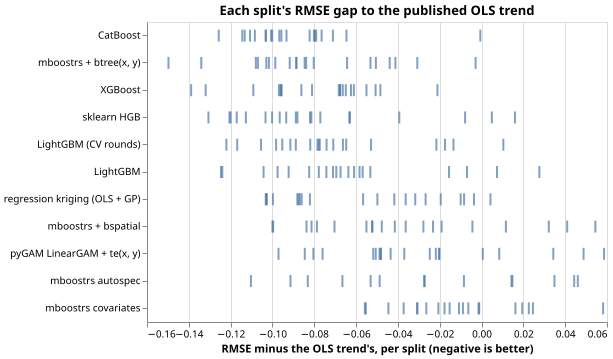

In [3]:
ORDER = ['CatBoost', 'mboostrs + btree(x, y)', 'XGBoost', 'sklearn HGB', 'LightGBM (CV rounds)', 'LightGBM', 'regression kriging (OLS + GP)', 'mboostrs + bspatial', 'pyGAM LinearGAM + te(x, y)', 'mboostrs autospec', 'mboostrs covariates', 'statsmodels OLS (published trend)']
per_split = (
    runs.filter(pl.col("status") == "success")
    .join(runs.filter(pl.col("method") == "statsmodels OLS (published trend)").select("seed", pl.col("rmse").alias("ols")), on="seed")
    .with_columns((pl.col("rmse") - pl.col("ols")).alias("difference"))
    .filter(pl.col("method") != "statsmodels OLS (published trend)")
)
alt.Chart(per_split).mark_tick(thickness=2, size=12).encode(
    x=alt.X("difference:Q", title="RMSE minus the OLS trend's, per split (negative is better)"),
    y=alt.Y("method:N", sort=ORDER, title=None),
).properties(width=460, height=300, title="Each split's RMSE gap to the published OLS trend")

## Failures and cost

`autospec`, the automatic specification search, failed on 6 of 20 splits with mboostrs 0.1.3. In each, its family probe (a trial fit of candidate response distributions) tried a gamma location-scale model (`GammaLSS`: each distribution parameter has its own additive predictor); the fit diverged and the Rust core aborted on a non-positive argument to the digamma function. The error reached Python as a `PanicException`, which a plain `except Exception` does not catch. When it finished, `autospec` proposed a `bspatial(x, y)` surface with the covariates, which is a sensible specification, at a median 16.2 s against 2.1 s for the hand-written equivalent.

The `bspatial` arm is also the costliest hand-written model: a median 2.1 s per split, nearly all of it inside `tune_mstop`, which cross-validates paths of up to 4253 steps and returns the final fit, and 82 MB of peak memory growth in the seed-0 probe. The `btree(x, y)` arm, which scores better, takes 0.03 s and 6 MB.

In [4]:
ORDER_KEY = pl.col("method").replace_strict({'CatBoost': 0, 'mboostrs + btree(x, y)': 1, 'XGBoost': 2, 'sklearn HGB': 3, 'LightGBM (CV rounds)': 4, 'LightGBM': 5, 'regression kriging (OLS + GP)': 6, 'mboostrs + bspatial': 7, 'pyGAM LinearGAM + te(x, y)': 8, 'mboostrs autospec': 9, 'mboostrs covariates': 10, 'statsmodels OLS (published trend)': 11}, default=99)
fails = failures(runs)
display(table(
    fails if fails.height else pl.DataFrame({"method": ["(none)"], "seed": [None], "error": [""]}),
    stub="method", stubhead="Method",
    title="Failed fits", subtitle="Each unsuccessful (method, seed) with the first line of its error",
    notes=["A failed seed is excluded from that method's means and counted in its failed column."],
))

GT(_tbl_data=shape: (6, 4)
┌───────────────────┬─────────┬──────┬─────────────────────────────────┐
│ method            ┆ variant ┆ seed ┆ error                           │
│ ---               ┆ ---     ┆ ---  ┆ ---                             │
│ str               ┆ null    ┆ i64  ┆ str                             │
╞═══════════════════╪═════════╪══════╪═════════════════════════════════╡
│ mboostrs autospec ┆ null    ┆ 1    ┆ PanicException: digamma requir… │
│ mboostrs autospec ┆ null    ┆ 4    ┆ PanicException: digamma requir… │
│ mboostrs autospec ┆ null    ┆ 6    ┆ PanicException: digamma requir… │
│ mboostrs autospec ┆ null    ┆ 10   ┆ PanicException: digamma requir… │
│ mboostrs autospec ┆ null    ┆ 13   ┆ PanicException: digamma requir… │
│ mboostrs autospec ┆ null    ┆ 17   ┆ PanicException: digamma requir… │
└───────────────────┴─────────┴──────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10e0ab170>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='variant', type=<ColInfoTypeEnum.default: 1>, column_label='variant', column_align='center', column_width=None), ColInfo(var='seed', type=<ColInfoTypeEnum.default: 1>, column_label='seed', column_align='right', column_width=None), ColInfo(var='error', type=<ColInfoTypeEnum.default: 1>, column_label='error', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ec34d70>, _spanners=Spanners([]), _heading=Heading(title='Failed fits', subtitle='Each unsuccessful (method, seed) with the first line of its error', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f925610>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f9ddf10>, _source_notes=["A failed seed is excluded from that method's means and counted in its failed column."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='variant', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='variant', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='variant', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='variant', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='variant', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='variant', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='seed', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='seed', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, mask=None), grpname=None, colname='seed', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F927B00>, ma

In [5]:
display(table(
    memory(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Peak memory of one fit",
    subtitle="Fresh process, seed 0: VmHWM after the fit minus VmRSS before it",
    labels={"seconds": "s", "peak_rss_growth_mb": "Δ RSS MB", "status": "status"},
    better={"peak_rss_growth_mb": "min"}, formats={"seconds": 2, "peak_rss_growth_mb": 1},
    notes=["The high-water mark is reset after imports and data loading, so the figure is the "
           "fit's own growth. One probe per method; descriptive, not averaged."],
))

GT(_tbl_data=shape: (12, 4)
┌─────────────────────────────────┬───────────┬────────────────────┬─────────┐
│ method                          ┆ seconds   ┆ peak_rss_growth_mb ┆ status  │
│ ---                             ┆ ---       ┆ ---                ┆ ---     │
│ str                             ┆ f64       ┆ f64                ┆ str     │
╞═════════════════════════════════╪═══════════╪════════════════════╪═════════╡
│ CatBoost                        ┆ 0.113482  ┆ 9.941406           ┆ success │
│ mboostrs + btree(x, y)          ┆ 0.036     ┆ 6.0078125          ┆ success │
│ XGBoost                         ┆ 0.064209  ┆ 9.621094           ┆ success │
│ sklearn HGB                     ┆ 0.105515  ┆ 1.953125           ┆ success │
│ LightGBM (CV rounds)            ┆ 0.061795  ┆ 7.1953125          ┆ success │
│ …                               ┆ …         ┆ …                  ┆ …       │
│ mboostrs + bspatial             ┆ 1.986582  ┆ 82.230469          ┆ success │
│ pyGAM LinearGAM + te(x, y)      ┆ 0.272049  ┆ 12.019531          ┆ success │
│ mboostrs autospec               ┆ 17.252446 ┆ 192.382812         ┆ success │
│ mboostrs covariates             ┆ 0.017496  ┆ 5.011719           ┆ success │
│ statsmodels OLS (published tre… ┆ 0.001654  ┆ 1.839844           ┆ success │
└─────────────────────────────────┴───────────┴────────────────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x10f9de300>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None), ColInfo(var='peak_rss_growth_mb', type=<ColInfoTypeEnum.default: 1>, column_label='Δ RSS MB', column_align='right', column_width=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10da77b60>, _spanners=Spanners([]), _heading=Heading(title='Peak memory of one fit', subtitle='Fresh process, seed 0: VmHWM after the fit minus VmRSS before it', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f9de0f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f9df6b0>, _source_notes=["The high-water mark is reset after imports and data loading, so the figure is the fit's own growth. One probe per method; descriptive, not averaged."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DE7B0>, mask=None), grpname=None, colname='seconds', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DE7B0>, mask=None), grpname=None, colname='seconds', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DE7B0>, mask=None), grpname=None, colname='seconds', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DE7B0>, mask=None), grpname=None, colname='seconds', rownum=10, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DE7B0>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DE7B0>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DE7B0>, mask=None), grpname=None, colname='peak_rss_growth_mb', r

In [6]:
display(table(
    warnings_by_method(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Warnings raised during the fits",
    subtitle="Distinct warning texts across all seeds, with one example",
    labels={"distinct_warnings": "distinct", "example": "example"},
    notes=["Methods that raised none are omitted."],
))
display(table(
    lines(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Lines of code per method",
    subtitle="Statements in each method's function in benches/bench_public_tasks.py",
    labels={"lines": "lines"},
    notes=["Docstrings, comments and blank lines are not counted. Shared helpers are not "
           "counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds "
           "row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal."],
))

GT(_tbl_data=shape: (4, 3)
┌────────────────────────┬───────────────────┬─────────────────────────────────┐
│ method                 ┆ distinct_warnings ┆ example                         │
│ ---                    ┆ ---               ┆ ---                             │
│ str                    ┆ i64               ┆ str                             │
╞════════════════════════╪═══════════════════╪═════════════════════════════════╡
│ mboostrs + btree(x, y) ┆ 9                 ┆ ExtrapolationWarning: 1 learne… │
│ mboostrs + bspatial    ┆ 8                 ┆ ExtrapolationWarning: 1 learne… │
│ mboostrs autospec      ┆ 88                ┆ ExtrapolationWarning: 1 learne… │
│ mboostrs covariates    ┆ 9                 ┆ ExtrapolationWarning: 1 learne… │
└────────────────────────┴───────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10da76f90>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='distinct_warnings', type=<ColInfoTypeEnum.default: 1>, column_label='distinct', column_align='right', column_width=None), ColInfo(var='example', type=<ColInfoTypeEnum.default: 1>, column_label='example', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ec9bc80>, _spanners=Spanners([]), _heading=Heading(title='Warnings raised during the fits', subtitle='Distinct warning texts across all seeds, with one example', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f9de3f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f9ddbb0>, _source_notes=['Methods that raised none are omitted.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='distinct_warnings', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='distinct_warnings', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='distinct_warnings', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='distinct_warnings', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='example', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='example', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='example', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DF170>, mask=None), grpname=None, colname='example', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10f9de600>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10f9ddd60>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, c

GT(_tbl_data=shape: (12, 2)
┌─────────────────────────────────┬───────┐
│ method                          ┆ lines │
│ ---                             ┆ ---   │
│ str                             ┆ i64   │
╞═════════════════════════════════╪═══════╡
│ CatBoost                        ┆ 2     │
│ mboostrs + btree(x, y)          ┆ 5     │
│ XGBoost                         ┆ 2     │
│ sklearn HGB                     ┆ 2     │
│ LightGBM (CV rounds)            ┆ 2     │
│ …                               ┆ …     │
│ mboostrs + bspatial             ┆ 5     │
│ pyGAM LinearGAM + te(x, y)      ┆ 5     │
│ mboostrs autospec               ┆ 4     │
│ mboostrs covariates             ┆ 5     │
│ statsmodels OLS (published tre… ┆ 2     │
└─────────────────────────────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x10f9dec90>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='lines', type=<ColInfoTypeEnum.default: 1>, column_label='lines', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e0d01d0>, _spanners=Spanners([]), _heading=Heading(title='Lines of code per method', subtitle="Statements in each method's function in benches/bench_public_tasks.py", preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f9dee10>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f9de3f0>, _source_notes=['Docstrings, comments and blank lines are not counted. Shared helpers are not counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DD2B0>, mask=None), grpname=None, colname='lines', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DD2B0>, mask=None), grpname=None, colname='lines', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DD2B0>, mask=None), grpname=None, colname='lines', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10F9DD2B0>, mask=None), grpname=None, colname='lines', rownum=10, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10f9ded20>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10f9de480>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', 

## Reproduction

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 MKL_NUM_THREADS=1 \
  python benches/bench_public_tasks.py --task spatial \
  --out docs/book/benchmarks/bench_public_spatial.json
```

This page reads the recorded artifact `bench_public_spatial.json` and refits nothing. The artifact records the source URL and sha256, the seeds, the tree settings, the thread environment, library versions, the runner's sha256, the commit and the machine. The runner `benches/bench_public_tasks.py` is not included in the repository; the recorded sha256 identifies the version that wrote the artifact.